In [46]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [47]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]

testes = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]


Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, as consegue separar. O problema não é o valor do limiar, é que o brilho não distingue fundo de peças. A solução é segmentar pela cor. Ou seja, em ves de ler a imagem em tons de cinzento, esta sera lida com as cores originais e usa-se o fundo azul como referência. 

Porque funciona: no fundo azul, B é bastante maior que R e G, mesmo nas zonas de sombra (fica mais escuro, mas continua azul). Nas peças isso não acontece: vermelha e laranja têm R alto, a verde tem G alto, a amarela tem R e G altos, e a bege/branca/cinzenta tem os três canais parecidos, logo B não ganha por margem. Os valores 40 e 20 são o ponto de partida, e deves ajustá-los vendo as máscaras.

O 255 - fundo funciona porque fundo é um array uint8 só com 0 e 255: onde era 255 (fundo) passa a 0, e onde era 0 (peça) passa a 255. Assim, o treino_bin tem todas as imagens em binario, ou seja, peças a branco e fundo a preto.

Medimos a instensidade em cada canal BGR em diferentes sítios na imagem (canto esquerdo, centro e canto direito), para ver o intervalo em que cada canal variava, e desta forma, definir de uma maneira mais rigorosa onde é o fundo, eliminando possíveis erros, como haver valores fora dos intervalos definidos e partes do fundo (como as bordas) serem detetadas como peças.  

Canto esquerdo:  [234 164  73]
Centro:  [198 124  66]
Canto direito [221 149  71]


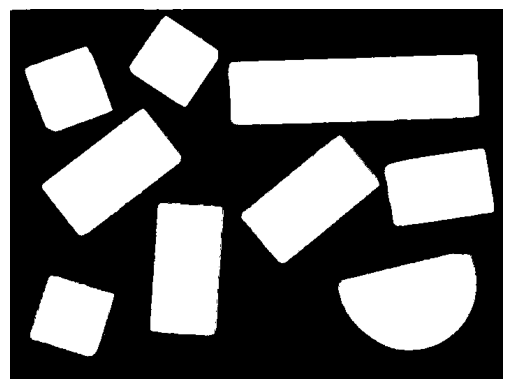

In [48]:

#Binarização

#treino_bin = [cv2.threshold(img, 140, 255, cv2.THRESH_BINARY)[1] for img in treino]

def segmentar(img):
    fundo = cv2.inRange(img, (150, 90, 0), (255, 200, 110))   # (B, G, R) min e max
    return 255 - fundo                                        # peças = branco, fundo = preto


#estes valores estão em bgr, pq a imagem foi lida assim
print("Canto esquerdo: ", treino[0][10, 10])      # canto
print("Centro: ", treino[0][260, 350])    # centro (zona de fundo)
print("Canto direito", treino[0][500, 20])     # outro canto
treino_bin = [segmentar(img) for img in treino]


plt.imshow(treino_bin[0],cmap="gray")
plt.axis("off")
plt.show()


#hist = cv2.calcHist([treino[2]], [0], None, [256], [0, 256])


Os Operadores Morfológicos limpam a imagem binaria antes da extração dos contornos. Faz-se abertura(erosão -> dilatação) para remover as partes brancas e mais pequenas que nao fazem parte das peças. Faz-se o fecho (dilatação -> erosão) para fechar pequenos buracos, como os reflexos nos pinos do Lego. A abertura vem primeiro para remover o ruído antes de fechar, senão o fecho consolidava os pontos de ruído junto às peças e podia voltar a ligar peças proximas. 

(Explicação da escolha dos elementos estruturantes)

Depois de separar as peças juntas, faz-se uma dilatação peça a peça, dando-lhes uma label, para as poder distinguir, permitindo aumentar o tamanho das peças, sem que elas se juntem novamente. 

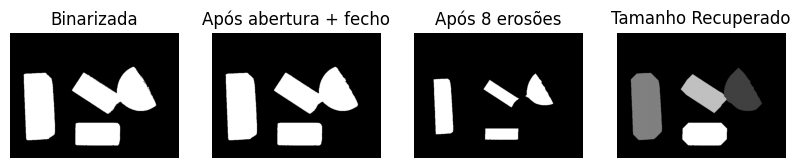

In [49]:
#Operadores Morfológicos

kernel_a = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7)) # elemento estruturante 
kernel_f = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3)) 

#
# O fecho é melhor 

# A função limpar aplica abertura seguida de fecho a uma imagem binária
# Problema: não separam peças muito próximas
def limpar(bin_):
    abertura = cv2.morphologyEx(bin_, cv2.MORPH_OPEN, kernel_a)    # abertura
    fecho = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, kernel_f)   # fecho
    return fecho

# A função separar aplica erosão a uma imagem limpa para separar as peças
# o 8 foi escolhido depois de testar com vários valores (célula a seguir)
def separar(limpa, it=8):
    return cv2.erode(limpa, kernel_a, iterations=it) 


#Percorre cada pixel "novo", e em cada pixel "novo", percorre cada peça para ver quem vai ficar com ela
def recuperar_tamanho(limpa, sep, it=8*3):
    # nº de passos: cada erosão com kernel 7x7 tem raio=3, por isso tira ~3 px, logo 8 erosões tira ≈ 24 px, para recuperar estes 24 px, faz-se dilatação 24 vezes, pq 
    #(3x3) tem raio 1. 

     # cada peça erodida = 1 label
    n, labels = cv2.connectedComponents(sep) 
    #connectedComponents devolve os labels num tipo que pode ser int32 (por defeito) ou uint16. Usou-se astype(np.int32) para garantir
    #um tipo que aguenta muitos labels
    labels = labels.astype(np.int32) 

    for _ in range(it):
        novo = labels.copy()

        # crescimento guarda, para cada pixel livre, qual a peça que o quer ocupar
        crescimento = np.zeros(labels.shape, np.int32) 
        # conflito marca com 1 os pixels que mais do que uma peça quis ocupar no mesmo passo. Esses pixels vão ficar vazios.
        conflito = np.zeros(labels.shape, np.uint8)

        ## dilata cada label separadamente (1 passo com kernel 3x3)
        for k in range(1, n):
            #compara a imagem de labels com o número k e cria uma imagem só com a peça k
            comp = (labels == k).astype(np.uint8) 
             #dilata essa peça 1 px
            dil = cv2.dilate(comp, kernel_f)
            # Calcula os pixels novos que a peça quer ocupar: estão a 1 na versão dilatada (dil == 1) e ainda estão livres (labels == 0), ninguém os ocupou
            nova_zona = (dil == 1) & (labels == 0)  
            # se o pixel já foi reclamado por outra peça neste passo -> conflito
            conflito[nova_zona & (crescimento != 0)] = 1 
            crescimento[nova_zona & (crescimento == 0)] = k

        # só aceita pixels dentro da máscara original e sem conflito
        aceitar = (crescimento != 0) & (conflito == 0) & (limpa > 0)
        novo[aceitar] = crescimento[aceitar]
        labels = novo

    return labels



treino_limpo = [limpar(b) for b in treino_bin]
treino_sep   = [separar(l) for l in treino_limpo]
treino_tam_org = [recuperar_tamanho(l, s) for l, s in zip(treino_limpo, treino_sep)]



fig, ax = plt.subplots(1, 4, figsize=(10, 4))

ax[0].imshow(treino_bin[6], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(treino_limpo[6], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")

ax[2].imshow(treino_sep[6], cmap="gray")
ax[2].set_title("Após 8 erosões")
ax[2].axis("off")

ax[3].imshow(treino_tam_org[6], cmap="gray")
ax[3].set_title("Tamanho Recuperado")
ax[3].axis("off")
plt.show()

In [50]:
# TESTE DE EROSÃO: para concluir quantas iterações de erosão são necessárias para separar peças em contacto

# idx = [0, 3, 4, 6]          # imagens com contactos entre peças e objetos de ruído, e uma imagem com várias peças
# its = [6, 7, 8]

# fig, ax = plt.subplots(len(idx), 2 + len(its), figsize=(14, 3 * len(idx)))

# for r, i in enumerate(idx):
#     ax[r, 0].imshow(treino_bin[i], cmap="gray")   
#     ax[r, 0].set_title("Binarizada")
#     ax[r, 1].imshow(treino_limpo[i], cmap="gray")
#     ax[r, 1].set_title("Abertura+fecho")

#     for c, it in enumerate(its):
#         ax[r, 2 + c].imshow(separar(treino_limpo[i], it), cmap="gray") 
#         ax[r, 2 + c].set_title(f"Erosão it={it}")

# for a in ax.ravel(): a.axis("off")
# plt.tight_layout()
# plt.show()

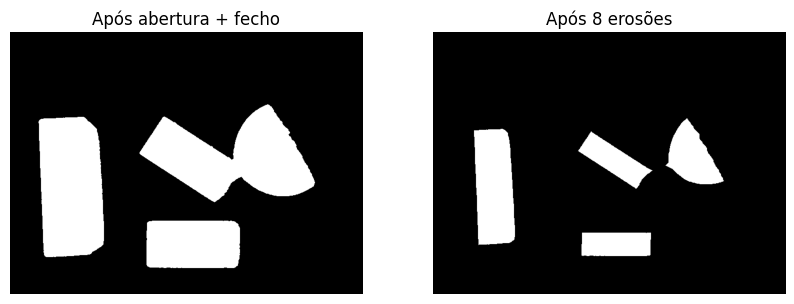

Imagem limpa:  3
Imagem com peças separadas:  4


In [51]:
# Etiquetação

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(treino_limpo[6], cmap="gray")
ax[0].set_title("Após abertura + fecho")
ax[0].axis("off")

ax[1].imshow(treino_sep[6], cmap="gray")
ax[1].set_title("Após 8 erosões")
ax[1].axis("off")
plt.show()

n_limpo, etiquetas_limpo = cv2.connectedComponents(treino_limpo[6]) # número de objetos, etiquetas
n_sep, etiquetas_sep = cv2.connectedComponents(treino_sep[6])
print("Imagem limpa: ", n_limpo - 1) # 0 é o fundo, daí subtraí-se 1
print("Imagem com peças separadas: ", n_sep - 1) 

# A imagem 6 tem 4 peças mas duas juntas, e usando a imagem limpa apenas se detetam 3 peças
# Na imagem com peças separadas já dá o resultado correto

4


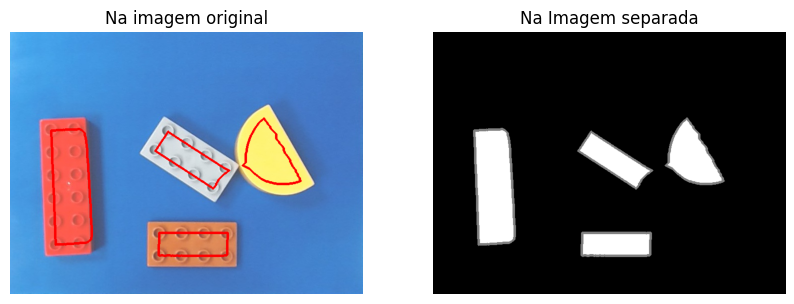

In [52]:
# findContours -> devolve umaa lista de pontos da fronteira, e cada contorno corresponde a um objeto.
# drawContours desenha esses contornos, ou preenche-os se thickness=-1, o que dá uma máscara por peça.
# Os contornos servem depois para o próximo passo

contornos, _ = cv2.findContours(treino_sep[6], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) 
# RETR_EXTERNAL apanha só os contornos exteriores
# CHAIN_APPROX_SIMPLE guarda só os pontos finais de cada linha (poupa memória)

print(len(contornos)) # número de objetos encontrados

img_org = treino[6].copy()
cv2.drawContours(img_org, contornos, -1, (0, 0, 255), 3)

img_sep = treino_sep[6].copy()
cv2.drawContours(img_sep, contornos, -1, 128, 3) # contornos a cinzento

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img_org[:, :, ::-1])
ax[0].set_title("Na imagem original")
ax[0].axis("off")

ax[1].imshow(img_sep, cmap="gray")
ax[1].set_title("Na Imagem separada")
ax[1].axis("off")
plt.show()

In [53]:
# Extração de Características



In [54]:
# Classificação

